# Reference Simulations and Physics Checks

> **About this notebook, version 1.0.0 (17 November 2026).** The third of five notebooks of *Polymer Neural Nets*. Equation numbers such as (10.2) refer to the theory notebook 00; the data files are described in notebook 01. Python 3.14 with NumPy, SciPy, Matplotlib and OpenMM.

*Before any network is trained, the reference data must pass the physics checks themselves: the scaling R_g ∼ N^ν, the local structure of bonds and angles, and energy conservation*

**Dara O Shayda**  
Republic of Ireland  
*dara@compclassnotes.com*  

**Noor Hoshino**  
<img alt="نور 星野" src="figures/noor-name.png" height="22">  
Advanced AI System Programming  
Hokkaido Prefecture, Japan  
*noor@compclassnotes.com*  
Computational Classnotes · revision 1  

<p align='left' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>

## Abstract

A learned force field is judged by what a simulation with it produces, so the yardstick must be set first. This notebook runs the three checks of the project brief on the reference simulations made with OpenMM. First, the size of the chain. Ideal chains of 16 to 128 beads follow $R_g \propto N^{1/2}$ and agree with the exact formula ⟨R_g²⟩ = (N² − 1)b²/(6N). Self-avoiding Kremer–Grest chains swell, with an effective exponent above 0.588 at these short lengths, for reasons explained in section 2. Pivot Monte Carlo, an entirely different sampling method, gives the same sizes up to 64 beads and a slightly smaller size at 128 beads, where the molecular dynamics has not fully relaxed. Second, the local structure: the distributions of bond lengths and bond angles, with the excluded angles below 60° explained. Third, energy conservation with the exact forces, whose error shrinks as Δt² as Theorem 10 of notebook 00 predicts. A short simulation is also run live, so the whole procedure can be repeated in a few seconds.

**Keywords:** Kremer–Grest chain; ideal chain; radius of gyration; Flory exponent; corrections to scaling; replica simulations; pivot Monte Carlo; bond-length distribution; bond-angle distribution; velocity Verlet; energy conservation; OpenMM

## Index

- Section 1, a live simulation: Table 1, cell c.1.
- Section 2, R_g ∼ N^ν: Eqs. (1)–(3), Figure 1, Tables 2–3, cells c.2–c.3.
- Section 3, bonds and angles: Eq. (4), Figure 2, Table 4, cell c.4.
- Section 4, energy conservation: Figure 3, Table 5, cell c.5.
- Section 5, what the networks must reproduce: Table 6.

## 0. Settings

Cell c.0 makes the notebook run in any Jupyter: it installs missing libraries, finds the repository folder or downloads it once from GitHub into `~/polymer-neural-nets` when this notebook is opened on its own, and sets the style of figures and tables.

In [1]:
# c.0
# Setup. This cell makes the notebook run in any Jupyter, three ways:
#  (1) inside the repository folder (e.g. `uv run jupyter lab`, or `pip install -r requirements.txt` then `jupyter lab`);
#  (2) in any Python environment: libraries that are missing are installed with pip into this kernel;
#  (3) as a single notebook file on its own: the code and data of the repository are downloaded once from
#      GitHub into the folder polymer-neural-nets in your home folder.
import importlib.util, subprocess, sys, io, zipfile, urllib.request, warnings
from pathlib import Path
warnings.filterwarnings("ignore")   # library notices (tqdm, TorchScript) are not part of the results
NEED = {"numpy": "numpy", "scipy": "scipy", "sympy": "sympy", "matplotlib": "matplotlib", "torch": "torch",
        "torch_geometric": "torch-geometric", "openmm": "openmm", "IPython": "ipython"}
missing = [pkg for mod, pkg in NEED.items() if importlib.util.find_spec(mod) is None]
if sys.platform == "emscripten":                                 # JupyterLite / Pyodide: Python inside the web page
    raise SystemExit("\n".join([
        "This Jupyter runs Python inside the web browser (JupyterLite / Pyodide, WebAssembly).",
        "PyTorch and OpenMM are not available there, and nothing can be installed with pip, so this notebook",
        "cannot run in it. The saved results are still shown in the notebook, and in the .md and .pdf editions.",
        "",
        "To run it, use Jupyter with a real Python on your computer. It also opens in the browser. In a terminal:",
        "  1. install uv (once):   curl -LsSf https://astral.sh/uv/install.sh | sh",
        "                          (Windows PowerShell: irm https://astral.sh/uv/install.ps1 | iex)",
        "  2. get the repository:  git clone https://github.com/lossofgenerality/polymer-neural-nets",
        "                          cd polymer-neural-nets",
        "  3. install and start:   uv sync   then   uv run jupyter notebook",
        "Then open this notebook in the Jupyter tab that appears and choose Kernel → Restart Kernel and Run All Cells."]))
def install(pkgs):
    """Install pkgs into the Python of this kernel; try pip, then uv; explain clearly if neither works."""
    import shutil
    tries = [[sys.executable, "-m", "pip", "install", *pkgs]]
    if shutil.which("uv"):
        tries.append(["uv", "pip", "install", "--python", sys.executable, *pkgs])
    errors = []
    for cmd in tries:
        try:
            r = subprocess.run(cmd, capture_output=True, text=True)
            if r.returncode == 0:
                importlib.invalidate_caches(); return
            errors.append(f"{' '.join(cmd[:4])} …: exit code {r.returncode}\n{(r.stderr or r.stdout)[-1200:]}")
        except OSError as e:
            errors.append(f"{' '.join(cmd[:4])} …: could not be started ({e})")
    managed = any("externally-managed" in e for e in errors)
    raise SystemExit("\n".join([
        "Could not install " + ", ".join(pkgs) + " into the Python of this Jupyter kernel:", "    " + sys.executable, "",
        *errors, "",
        "Fix it in a terminal, in the folder of this repository, with one of these, then restart the kernel:",
        "  (a) uv:   uv sync   and then   uv run jupyter notebook      (uses the exact versions of uv.lock)",
        "  (b) venv: python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt && jupyter notebook",
        "            (Windows: .venv\\Scripts\\activate)",
        f"  (c) this kernel's Python: \"{sys.executable}\" -m pip install " + " ".join(pkgs),
        "This Python is managed by the system or Homebrew and refuses installs: use (a) or (b)." if managed else ""]))
if missing:
    print("installing", ", ".join(missing), "(first run only; torch is large) ...")
    install(missing)
def find_repo():
    for q in [Path.cwd(), *Path.cwd().parents]:                  # (1) this notebook is inside the repository
        if (q / "src" / "polymer_nn").is_dir() and (q / "data").is_dir():
            return q
    home = Path.home() / "polymer-neural-nets"                    # (3) download it once
    if not (home / "src" / "polymer_nn").is_dir():
        url = "https://github.com/lossofgenerality/polymer-neural-nets/archive/refs/heads/main.zip"
        print("downloading the repository (code, data, models) from", url)
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
            top = z.namelist()[0].split("/")[0]
            for m in z.infolist():
                rel = m.filename[len(top) + 1:]
                if rel and not m.is_dir():
                    (home / rel).parent.mkdir(parents=True, exist_ok=True)
                    (home / rel).write_bytes(z.read(m))
    return home
ROOT = find_repo()
sys.path.insert(0, str(ROOT / "src"))                             # use the repository's polymer_nn
import json, math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from polymer_nn import nbtools as nb
from polymer_nn.nbtools import table, nform, sci, savefig, figFont, wFull, wHalf, red, blue, green, orange, grey
nb.setup(threads=2)                 # plot style and 2 CPU threads; figures are saved in ./figures
DATA = ROOT / "data"                # the reference data made by scripts/generate_data.py
torch.manual_seed(0); rng = np.random.default_rng(0)
print("repository folder:", ROOT.name, "| Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__)

repository folder: polymer-neural-nets | Python 3.14.6 | torch 2.15.0+cu132 | numpy 2.5.5


## 1. A live simulation

`polymer_nn.sim.sample` runs one chain: it builds the OpenMM system with the FENE and WCA potentials (notebook 00, Eq. (10.6)), starts from a random walk, minimises the energy, equilibrates with Langevin dynamics at k_BT = 1, and records frames. Cell c.1 runs a 16-bead chain for 200 frames, which takes a few seconds, and checks the basic numbers. The mean bond length should be close to 0.97 σ, the known value for the Kremer–Grest model. The mean kinetic energy per bead should be (3/2) k_BT, by equipartition.

In [2]:
# c.1
# a live Kremer-Grest simulation: 16 beads, 200 frames
from polymer_nn.sim import ChainSpec, sample, make_context
from polymer_nn import analysis as A
t0 = time.time()
demo = sample(ChainSpec(n_beads=16, model="kg", seed=11), n_frames=200, stride=100, equilibrate=5000)
ctx, integ = make_context(ChainSpec(n_beads=16, seed=11)); integ.step(5000); Ks = []
for k in range(200):
    integ.step(20); Ks.append(ctx.getState(getEnergy=True).getKineticEnergy()._value)
table([["quantity", "value", "expected"], ["wall time for 25 000 + 20 000 steps", f"{time.time() - t0:.1f} s", ""],
       ["mean bond length (σ)", f"{A.bond_lengths(demo['positions']).mean():.4f}", "≈ 0.97 (Kremer–Grest)"],
       ["⟨R_g²⟩^½ (σ)", f"{np.sqrt(np.mean(A.radius_of_gyration(demo['positions'])**2)):.3f}", "≈ 2.3 (section 2)"],
       ["mean kinetic energy per bead (ε)", f"{np.mean(Ks) / 16:.3f}", "1.5 = (3/2) k_BT"],
       ["mean potential energy per bead (ε)", f"{demo['energy'].mean() / 16:.3f}", "springs + WCA shifts"]], "Table 1. A 16-bead chain, live")

quantity,value,expected
wall time for 25 000 + 20 000 steps,7.3 s,
mean bond length (σ),0.9710,≈ 0.97 (Kremer–Grest)
⟨R_g²⟩^½ (σ),2.179,≈ 2.3 (section 2)
mean kinetic energy per bead (ε),1.510,1.5 = (3/2) k_BT
mean potential energy per bead (ε),19.433,springs + WCA shifts


## 2. The size of the chain: R_g ∼ N^ν

The radius of gyration R_g measures the size of a chain (Eq. (A1) of `polymer_nn.analysis`). For long chains it grows as a power of the length (notebook 00, section 10):

$$
\langle R_g^2 \rangle^{1/2} = b\, N^{\nu} \quad \text{with} \quad \nu = \tfrac12 \ (\text{ideal}), \qquad \nu = 0.5876 \ (\text{self-avoiding}) \tag{1}
$$

and for the ideal chain exactly

$$
\langle R_g^2 \rangle = \frac{(N^2 - 1)\, \langle b^2 \rangle}{6N} . \tag{2}
$$

**How the reference values were obtained.** For each N = 16, 32, 64, 128 and each model, `scripts/generate_data.py --scaling` ran R independent chains in one OpenMM system: R = 8 for Kremer–Grest, 16 for the ideal chain. The chains were placed 1000 σ apart, so they never meet. A low friction γ = 0.1/τ was used, which makes the chains move faster without changing their equilibrium shapes. Each Kremer–Grest chain was first relaxed by 3000 pivot moves, then equilibrated by 10⁵ MD steps (500 τ) and sampled for 200 frames 1000 steps apart. The error bar is the standard error of the R per-chain averages. These are truly independent, unlike successive frames of one chain.

**An independent check.** Starting from the final MD frame of every chain, 4000 pivot Monte Carlo moves were run (notebook 00, Theorem 11). Pivot moves sample the same distribution by a completely different mechanism, so agreement between MD and pivot MC means that the MD has sampled its equilibrium.

**Fitting ν.** ν is the slope of log R_g against log N. At these short lengths, R_g also has corrections to scaling,

$$
\langle R_g^2 \rangle^{1/2} = b\, N^{\nu} \bigl(1 + a N^{-\Delta} + \dots\bigr) , \qquad \Delta \approx 0.5 , \tag{3}
$$

and the local stiffness of the Kremer–Grest chain also contributes: the i, i+2 repulsion forbids sharp angles. Both raise the apparent exponent between N = 16 and N = 128 above 0.588. The local exponents between successive N (Table 3) show how the slope changes with N.

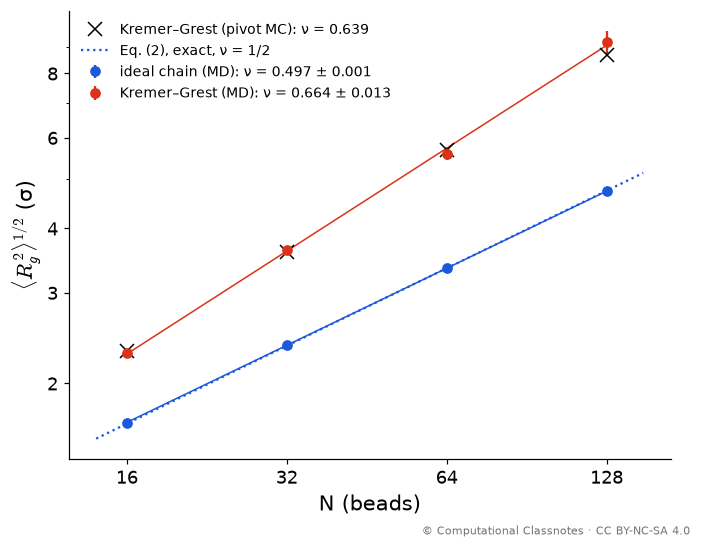

N,ideal: MD,ideal: Eq. (2),KG: MD ± s.e.,KG: pivot MC,KG: MD − pivot
16,1.679,1.671,2.292 ± 0.004,2.312,-0.8 %
32,2.372,2.367,3.637 ± 0.018,3.604,+0.9 %
64,3.354,3.348,5.587 ± 0.079,5.679,-1.6 %
128,4.720,4.736,9.204 ± 0.236,8.695,+5.9 %


In [3]:
# c.2
# R_g against N for the ideal and the Kremer-Grest chain; exact ideal-chain formula; pivot-MC check
S = {m: np.load(DATA / f"scaling_{m}.npz") for m in ("ideal", "kg")}
fig, ax = plt.subplots(figsize=(wFull * 1.05, wFull * 0.82)); fits = {}
for m, c, lab in [("ideal", blue, "ideal chain (MD)"), ("kg", red, "Kremer–Grest (MD)")]:
    N, rg = S[m]["sizes"], S[m][f"{m}_rg"]; fits[m] = f = A.fit_flory_exponent(N, rg)
    ax.errorbar(N, rg, yerr=2 * S[m][f"{m}_rg_sem"], fmt="o", color=c, label=f"{lab}: ν = {f.nu:.3f} ± {f.nu_err:.3f}")
    ax.plot(N, f.prefactor * N**f.nu, color=c, lw=1)
fp = A.fit_flory_exponent(S["kg"]["sizes"], S["kg"]["kg_pivot_rg"]); fits["kg, pivot MC"] = fp
ax.plot(S["kg"]["sizes"], S["kg"]["kg_pivot_rg"], "x", color="k", ms=9, label=f"Kremer–Grest (pivot MC): ν = {fp.nu:.3f}")
b2 = np.mean(A.bond_lengths(S["ideal"]["ideal_final_N128"]) ** 2)
Nf = np.geomspace(14, 150, 50); ax.plot(Nf, np.sqrt((Nf**2 - 1) / (6 * Nf) * b2), ":", color=blue, label="Eq. (2), exact, ν = 1/2")
ax.set(xscale="log", yscale="log", xlabel="N (beads)", ylabel=r"$\langle R_g^2\rangle^{1/2}$ (σ)"); nb.logticks(ax, [16, 32, 64, 128], [2, 3, 4, 6, 8])
ax.legend(fontsize=9); fig.tight_layout(); savefig(fig, "fig1_scaling"); plt.show()
rows = [["N", "ideal: MD", "ideal: Eq. (2)", "KG: MD ± s.e.", "KG: pivot MC", "KG: MD − pivot"]]
for k, N in enumerate(S["kg"]["sizes"]):
    th = np.sqrt((N**2 - 1) / (6 * N) * b2)
    rows.append([int(N), f"{S['ideal']['ideal_rg'][k]:.3f}", f"{th:.3f}", f"{S['kg']['kg_rg'][k]:.3f} ± {S['kg']['kg_rg_sem'][k]:.3f}",
                 f"{S['kg']['kg_pivot_rg'][k]:.3f}", f"{(S['kg']['kg_rg'][k] / S['kg']['kg_pivot_rg'][k] - 1) * 100:+.1f} %"])
table(rows, f"Table 2. ⟨R_g²⟩^½ in σ (ideal chain: ⟨b²⟩ = {b2:.4f} σ²)")

*Figure 1. Size against length on log–log axes. Ideal chains (blue) lie on the exact result of Eq. (2) and have slope 1/2. Kremer–Grest chains (red) are larger and steeper. Pivot Monte Carlo (crosses) agrees with the MD up to N = 64.*

In [4]:
# c.3
# local exponents between successive N and the fits
rows = [["chain", "N₁ → N₂", "local exponent log(R₂/R₁)/log(N₂/N₁)"]]
for m, key in [("ideal", "ideal_rg"), ("kg", "kg_rg"), ("kg", "kg_pivot_rg")]:
    N, rg = S[m]["sizes"], S[m][key]
    for i in range(len(N) - 1):
        rows.append([m + (" (pivot MC)" if "pivot" in key else " (MD)"), f"{N[i]} → {N[i + 1]}", f"{np.log(rg[i + 1] / rg[i]) / np.log(N[i + 1] / N[i]):.3f}"])
table(rows + [["fits over all N", "", "; ".join(f"{k}: {v}" for k, v in fits.items())]], "Table 3. Local and fitted exponents")

chain,N₁ → N₂,local exponent log(R₂/R₁)/log(N₂/N₁)
ideal (MD),16 → 32,0.498
ideal (MD),32 → 64,0.500
ideal (MD),64 → 128,0.493
kg (MD),16 → 32,0.666
kg (MD),32 → 64,0.619
kg (MD),64 → 128,0.720
kg (pivot MC),16 → 32,0.641
kg (pivot MC),32 → 64,0.656
kg (pivot MC),64 → 128,0.615
fits over all N,,"ideal: nu = 0.497 ± 0.001; kg: nu = 0.664 ± 0.013; kg, pivot MC: nu = 0.639 ± 0.006"


How to read Tables 2–3. The ideal chain behaves exactly as theory says: every local exponent is close to 1/2, and the sizes agree with Eq. (2) to within about 1%. For the Kremer–Grest chain, MD and pivot MC agree within about 2% up to N = 64. At N = 128 the MD value is about 5% larger. Pivot MC relaxes the overall shape in a few moves, while MD needs many Rouse times, $\tau_R \propto N^{1+2\nu}$. The MD chains of 128 beads therefore have not fully forgotten their starting shapes, so for N = 128 the pivot value is the more reliable one. All model checks in notebook 04 use N ≤ 64, where both methods agree. The effective exponent of the Kremer–Grest chain over N = 16–128 is about 0.64–0.66, above the asymptotic 0.588 as expected from Eq. (3). What matters for a learned force field is that it reproduces these numbers at the same N.

## 3. Bonds and angles

The local structure of the chain is described by two distributions: the bond lengths $|x_{i+1} - x_i|$ and the bond angles θ_i, the angle at bead i between its two bonds (θ = 180° for a straight chain):

$$
\cos \theta_i = \frac{(x_{i-1} - x_i) \cdot (x_{i+1} - x_i)}{|x_{i-1} - x_i|\, |x_{i+1} - x_i|} \tag{4}
$$

The bond-length distribution comes from the Boltzmann factor of the bond potential: $P(r) \propto r^2 e^{-U(r)/k_BT}$, with U = FENE + WCA (notebook 00, Eq. (2.7)), where r² is the area of a sphere of radius r. The bond angle has no potential of its own, but beads i − 1 and i + 1 repel each other through WCA. With bonds of 0.97 σ, an angle of 60° puts them 0.97 σ apart, deep inside the steep WCA wall, so angles below about 60° are rare and angles below about 55° practically never occur. Cell c.4 checks the measured bond-length distribution against P(r).

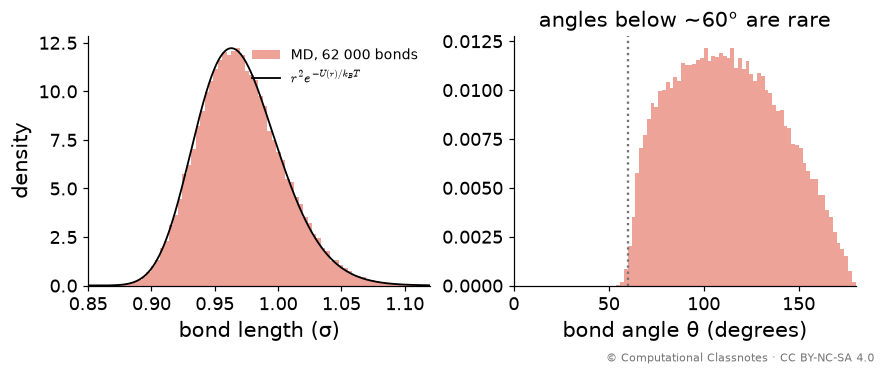

quantity,MD,from P(r)
mean bond length (σ),0.9710,0.9701
standard deviation (σ),0.0339,0.0334
smallest angle seen (°),54.1,"≈ 55–60, set by WCA between i − 1 and i + 1"
mean angle (°),112.4,


In [5]:
# c.4
# bond-length and bond-angle distributions of the training data; bond lengths against P(r) ∝ r² exp(-U)
d32 = np.load(DATA / "kg_N32.npz"); bl = A.bond_lengths(d32["positions"]); ba = np.degrees(A.bond_angles(d32["positions"]))
rgrid = np.linspace(0.8, 1.2, 801)
Ub = -0.5 * 30 * 1.5**2 * np.log(1 - (rgrid / 1.5)**2) + np.where(rgrid < 2**(1/6), 4 * (rgrid**-12 - rgrid**-6) + 1, 0)
Pr = rgrid**2 * np.exp(-Ub); Pr /= np.trapezoid(Pr, rgrid)
fig, ax = plt.subplots(1, 2, figsize=(wFull * 1.3, wHalf * 1.15))
ax[0].hist(bl, bins=80, density=True, color=red, alpha=.45, label="MD, 62 000 bonds"); ax[0].plot(rgrid, Pr, color="k", lw=1.2, label=r"$r^2 e^{-U(r)/k_BT}$")
ax[0].set(xlabel="bond length (σ)", ylabel="density", xlim=(0.85, 1.12)); ax[0].legend(fontsize=9)
ax[1].hist(ba, bins=90, range=(0, 180), density=True, color=red, alpha=.45); ax[1].axvline(60, color=grey, ls=":")
ax[1].set(xlabel="bond angle θ (degrees)", title="angles below ~60° are rare", xlim=(0, 180))
fig.tight_layout(); savefig(fig, "fig2_bonds_angles"); plt.show()
mean_th = np.trapezoid(rgrid * Pr, rgrid); sd_th = np.sqrt(np.trapezoid((rgrid - mean_th)**2 * Pr, rgrid))
table([["quantity", "MD", "from P(r)"], ["mean bond length (σ)", f"{bl.mean():.4f}", f"{mean_th:.4f}"],
       ["standard deviation (σ)", f"{bl.std():.4f}", f"{sd_th:.4f}"], ["smallest angle seen (°)", f"{ba.min():.1f}", "≈ 55–60, set by WCA between i − 1 and i + 1"],
       ["mean angle (°)", f"{ba.mean():.1f}", ""]], "Table 4. Local structure of the training data")

*Figure 2. Left: bond lengths from MD (histogram) and the distribution $r^2 e^{-U(r)/k_BT}$ predicted by the bond potential alone (line). The small difference comes from the non-bonded neighbours, which also push on the beads. Right: bond angles. Below about 60° the two beads next to a bead would overlap, so such angles are rare.*

## 4. Energy conservation with the exact forces

Without a thermostat the total energy H = K + E must stay constant (notebook 00, Theorem 8), and with velocity Verlet its fluctuations must shrink as Δt² (Theorem 10). Cell c.5 runs the exact OpenMM forces with `polymer_nn.md.velocity_verlet` at three time steps, starting from a training frame. This sets the baseline a learned force field must match in notebook 04.

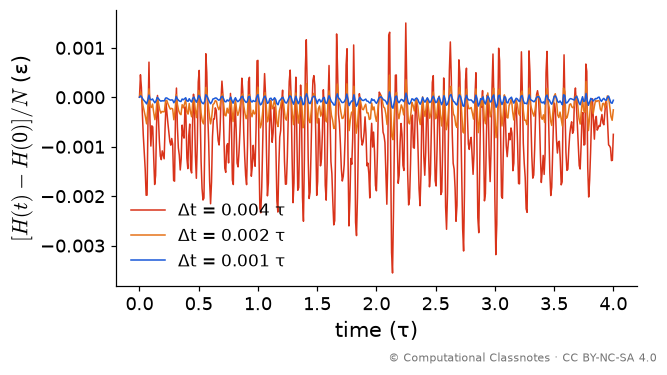

Δt (τ),drift of H per bead per τ,std of H per bead,ratio of std to the next Δt
0.004,6.8 × 10⁻⁶,8.5 × 10⁻⁴,
0.002,-2.1 × 10⁻⁶,2.2 × 10⁻⁴,3.90
0.001,-1.3 × 10⁻⁶,5.5 × 10⁻⁵,3.96


In [6]:
# c.5
# NVE with the exact forces at three time steps
from polymer_nn.md import reference_potential, velocity_verlet
x0 = d32["positions"][-1].astype(float); rows = [["Δt (τ)", "drift of H per bead per τ", "std of H per bead", "ratio of std to the next Δt"]]
fig, ax = plt.subplots(figsize=(wFull, wHalf * 1.15)); prev = None
for dt, c in zip((0.004, 0.002, 0.001), (red, orange, blue)):
    r = velocity_verlet(reference_potential(32), x0, n_steps=int(4 / dt), dt=dt, record_every=max(1, int(4 / dt) // 400))
    dd = A.energy_drift(r["time"], r["total"], 32)
    rows.append([dt, sci(dd["drift_per_bead_per_tau"]), sci(dd["std_per_bead"]), "" if prev is None else f"{prev / dd['std_per_bead']:.2f}"]); prev = dd["std_per_bead"]
    ax.plot(r["time"], (r["total"] - r["total"][0]) / 32, color=c, lw=1, label=f"Δt = {dt} τ")
ax.set(xlabel="time (τ)", ylabel=r"$[H(t) - H(0)]/N$ (ε)"); ax.legend(); fig.tight_layout(); savefig(fig, "fig3_nve_reference"); plt.show()
table(rows, "Table 5. Energy conservation with the exact forces (32 beads, 4 τ)")

*Figure 3. The total energy per bead in constant-energy runs with the exact forces. It fluctuates without drifting, and halving Δt divides the fluctuation by about 4, as Theorem 10 predicts.*

Halving Δt divides the fluctuations by about four, which is the Δt² law of notebook 00, Eq. (9.2). At Δt = 0.002 τ the fluctuation is about 2 × 10⁻⁴ ε per bead, against a kinetic energy of 1.5 ε per bead.

## 5. What the networks must reproduce

*Table 6. The targets for a learned force field (from Tables 2–5).*

| check | reference value | where it is tested |
|---|---|---|
| ⟨R_g²⟩^½ at N = 16, 32, 64 | 2.29, 3.64, 5.59 σ (MD); pivot MC 2.31, 3.60, 5.68 σ | notebook 04, chains of 16 and 64 beads never seen in training |
| effective ν over N = 16–64 | ≈ 0.64 | notebook 04 |
| mean bond length | 0.971 σ | notebook 04, OpenMM driven by the network |
| bond angles | rare below ≈ 60°, mean ≈ 112° | notebook 04 |
| NVE fluctuation at Δt = 0.002 τ | ≈ 2 × 10⁻⁴ ε per bead, no drift | notebook 04 |

## References

- [kremer1990] K. Kremer, G. S. Grest, J. Chem. Phys. 92 (1990) 5057–5086. doi:10.1063/1.458541
- [clisby2010] N. Clisby, Phys. Rev. Lett. 104 (2010) 055702. doi:10.1103/PhysRevLett.104.055702
- [madras1988] N. Madras, A. D. Sokal, J. Stat. Phys. 50 (1988) 109–186. doi:10.1007/BF01022990
- [rubinstein2003] M. Rubinstein, R. H. Colby, Polymer Physics, Oxford University Press (2003): ideal chains, Flory theory, Rouse dynamics.
- [eastman2017] P. Eastman et al., OpenMM 7, PLOS Comput. Biol. 13 (2017) e1005659. doi:10.1371/journal.pcbi.1005659
- The complete bibliography: `docs/REFERENCES.md`.

<p align='center' style='color:#666666'><i>© Computational Classnotes · CC BY-NC-SA 4.0</i></p>